In [14]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix,ConfusionMatrixDisplay

In [23]:
df = pd.read_csv('emails.csv')

print(df.head())
print(df.shape)
print(df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
print(df.columns[-5:])
print(df.describe())
print(df.columns.tolist())

  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]
(5172, 3002)
0
Duplicates: 0
Index(['military', 'allowing', 'f

In [16]:
df = df.dropna()
df = df.drop_duplicates()

df = df.drop('Email No.', axis=1)

print("Cleaned shape:", df.shape)

Cleaned shape: (5172, 3001)


In [17]:
X = df.drop('Prediction', axis=1)
y = df['Prediction']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

svm = SVC()
svm.fit(X_train, y_train)


Models trained successfully



--- KNN ---
Accuracy: 0.8338164251207729
              precision    recall  f1-score   support

           0       0.98      0.78      0.87       735
           1       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035

Confusion Matrix:
[[576 159]
 [ 13 287]]


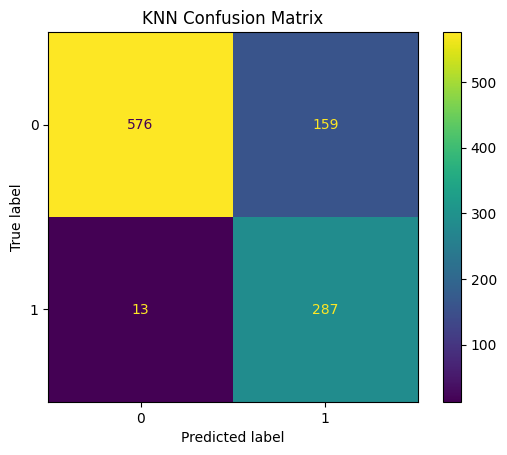


--- SVM ---
Accuracy: 0.9304347826086956
              precision    recall  f1-score   support

           0       0.91      0.99      0.95       735
           1       0.98      0.77      0.87       300

    accuracy                           0.93      1035
   macro avg       0.95      0.88      0.91      1035
weighted avg       0.93      0.93      0.93      1035

Confusion Matrix:
[[731   4]
 [ 68 232]]


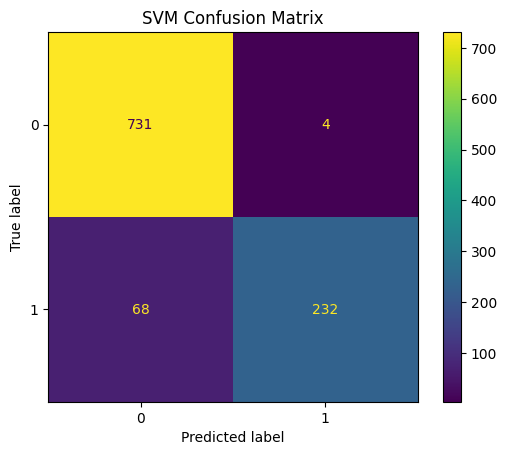

In [19]:
for name, model in [('KNN', knn), ('SVM', svm)]:
    pred = model.predict(X_test)

    print(f"\n--- {name} ---")
    print("Accuracy:", accuracy_score(y_test, pred))
    print(classification_report(y_test, pred))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, pred))

    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test)
    plt.title(f'{name} Confusion Matrix')
    plt.show()

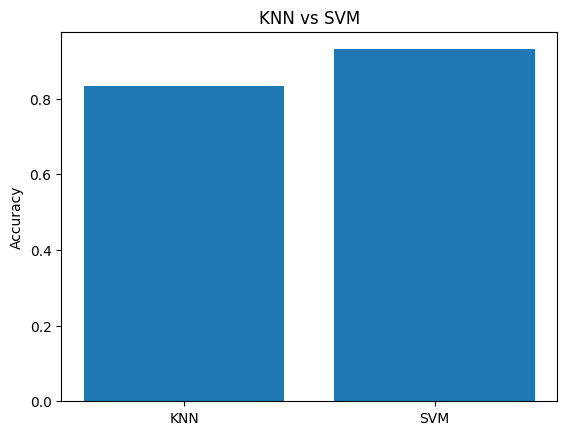

In [24]:
knn_acc = accuracy_score(y_test, knn.predict(X_test))
svm_acc = accuracy_score(y_test, svm.predict(X_test))

plt.bar(['KNN', 'SVM'], [knn_acc, svm_acc])

plt.ylabel('Accuracy')
plt.title('KNN vs SVM')
plt.show()